In [85]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [104]:
# Lets generate the synthetic dataset

def syn_data_gen(n : int):
      """ 
      Input n : number of sample data points (x, y)
      Output : x be points sampled from linear space or randomly generated
      with y = w0 + w2X  + noise(n, 0)
      """
      w0 = 4.0
      w1 = 3.0
      x = 10 * np.random.rand(n, )
      y = w0 + w1*x + np.random.randn(n, )
      return x, y

X, y = syn_data_gen(100)
print(f"Shape of feature matrix : {X.shape} \n label matrix : {y.shape}")    


Shape of feature matrix : (100,) 
 label matrix : (100,)


In [105]:
# split the dataset into the training and testing 
from sklearn.model_selection import train_test_split

X_train, y_train, X_test, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Shape of train feature matrix: {X_train.shape}\
      Shape of train label matrix : {y_train.shape} \
        Shape of test feature matrix : {X_test.shape} \
            Shape of test label matrix : {y_test.shape}")

Shape of train feature matrix: (80,)      Shape of train label matrix : (20,)         Shape of test feature matrix : (80,)             Shape of test label matrix : (20,)


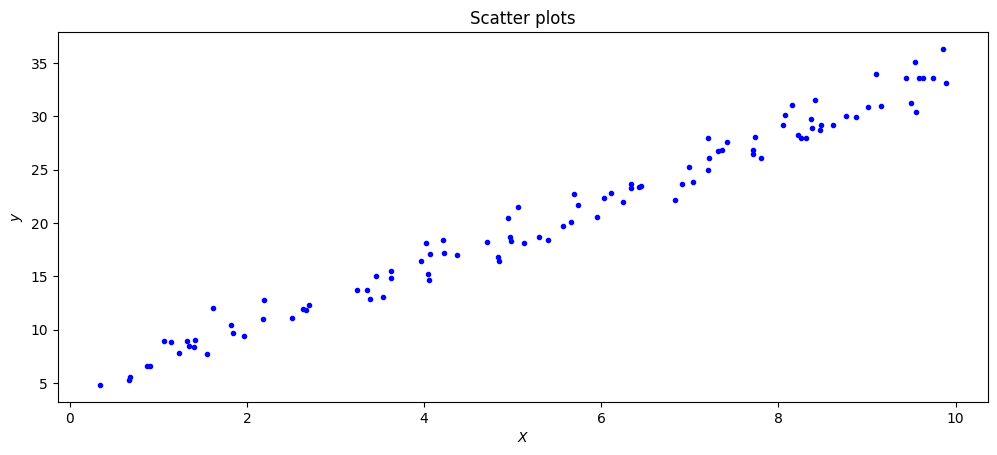

In [106]:
# visualize our dataset
def make_slrplot(X, y):
    plt.figure().set_figwidth(12)
    plt.plot(X, y, "b.")
    plt.title("Scatter plots")
    plt.xlabel("$X$")
    plt.ylabel("$y$")
    plt.show()

make_slrplot(X, y)

In [107]:
# adding dummy features to the feature matrix

def add_dummy_feature(X):
    return np.column_stack((np.ones(X.shape[0]), X))

print(f"Feature matrix before dummy features : {X_train[:5]}\n")
X_train_dummy = add_dummy_feature(X_train)
print(f"The feature matrix after dummy feature addition : {X_train_dummy[:5]}")

Feature matrix before dummy features : [6.83183856 9.49306797 6.24761271 4.71065453 2.50730661]

The feature matrix after dummy feature addition : [[1.         6.83183856]
 [1.         9.49306797]
 [1.         6.24761271]
 [1.         4.71065453]
 [1.         2.50730661]]


In [108]:
print(f"{X_train_dummy.shape} and {y_train.shape}")

(80, 2) and (20,)


In [169]:
# but we have to preprocess entire dataset thus
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
def preprocessing(X, y):
    X = add_dummy_feature(X)
    scaler.fit_transform(X)
    return train_test_split(X, y)

X_train, X_test, y_train, y_test = preprocessing(X, y)

In [170]:
# normal linear equation
# X @ w = y => w = inv(X) @ y
def weights(X, y):
    w = np.linalg.pinv(X) @ y
    return w

w = weights(X_train, y_train)
w[:]

array([4.25719946, 2.99265592])

In [171]:
# prediction for given input and weights we learn
def predict(X, w):
    """ 
    Input X(n, m+1) : feature matrix shape
    Output w(m+1, ) : shape of weight matrix
    return y(n, ) : vector of shape.
    """
    # check matrix compatibility
    assert X.shape[-1] == w.shape[0], "X and w don't have compatible shape for matrix multiplication"
    #y = X @ w
    #return y
    return X.dot(w)

In [172]:
# loss function 
def loss(X, y, w):
    y_pred = predict(X, w)
    #err = predict(X, w) - y
    #se = 1/2*(np.transpose(err) @ err)
    return np.mean((y_pred - y)**2) / 2

lf = loss(X_train, y_train, w)
lf

0.7034803768295128

In [173]:
# gradient computation
def gradient(X, y, w):
    """ 
    grad of loss function(scalar) wrt to weights(vector) on training data
    X: Feature matrix for training data.
        y: Label vector for training data
        w: Weight vector

    Returns:
        A vector of gradients.
    """
    #grad = np.transpose(X) @ (predict(X, w) - y)
    #return grad
    y_pred = predict(X, w)
    return X.T.dot(y_pred - y) / len(y)

grad = gradient(X_train, y_train, w)
grad

array([1.36542629e-14, 8.25798689e-14])

In [174]:
# define the weights updates
def update(w_old, grad, lr):
    """
    w_new := w_old - lr * grad
    Args:
        1. w: Weight vector
        2. grad: gradient of loss w.r.t w
        3. lr: learning rate

    Returns:
        Updated weight vector
    """
    w_new = w_old - lr * grad
    return w_new

w_1 = update(w, grad, lr=0.1)
print(f"W_old : {w}, W_new : {w_1}")

W_old : [4.25719946 2.99265592], W_new : [4.25719946 2.99265592]


### Gradient Descent Algorithm
What is gradient descent ?
I will provide answer to this question later but before that we have to understand why do we need gradient descent ? From the previous results you have seen that we have to compute the loss function and its gradient in every pass of dataset and update the weights of our linear model such that after many iteration converges to capture the pattern exists into the data.

We use the gradient descent algorithm for the estimation of parameters of the models through computation of gradient of the loss function that guide us to move towards the minimum loss.

### 1. Standard Gradient Descent Algorithm

In [153]:
def gradient_descent(X, y, lr, num_epochs):
    """
    Estimates parameters of linear regression model through gradient descent.
    """
    w_all = []  # all parameter vectors
    err_all = []  # all errors

    # parameter vector initialised to zero
    w = np.zeros(X.shape[1])

    for i in range(num_epochs):
        w_all.append(w.copy())
        err_all.append(loss(X, y, w))

        # gradient computation
        dJdW = gradient(X, y, w)

        if i % 100 == 0:
            print(f"Iteration {i}, Loss: {err_all[-1]:.4f}")

        # weight update
        w = update(w, dJdW, lr)

    return w, err_all, w_all


In [154]:
# Run gradient descent
w, err_all, w_all = gradient_descent(X_train, y_train, lr=0.01, num_epochs=200)


Iteration 0, Loss: 243.0608
Iteration 100, Loss: 1.6550


In [157]:
# learning curve during gradient descent training of model
def plot_learning(err_all):
    plt.plot(err_all)
    plt.xlabel("Iteration #")
    plt.ylabel('Loss : $J(\mathbf{w})$')

Iteration 0, Loss: 243.0608
Iteration 100, Loss: 1.6550


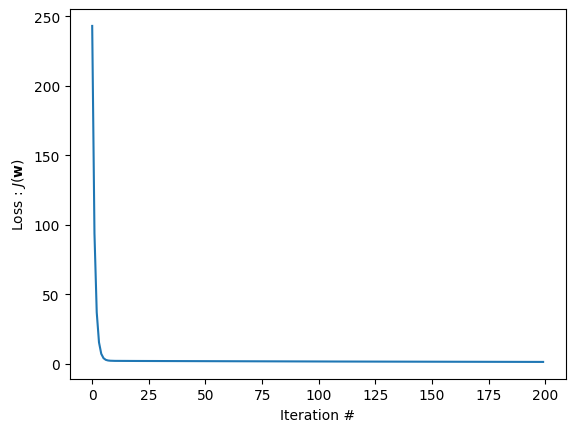

In [158]:
# Run gradient descent
w, err_all, w_all = gradient_descent(X_train, y_train, lr=0.01, num_epochs=200)
plot_learning(err_all)

In [145]:
import matplotlib.animation as animation


<function matplotlib.pyplot.show(close=None, block=None)>

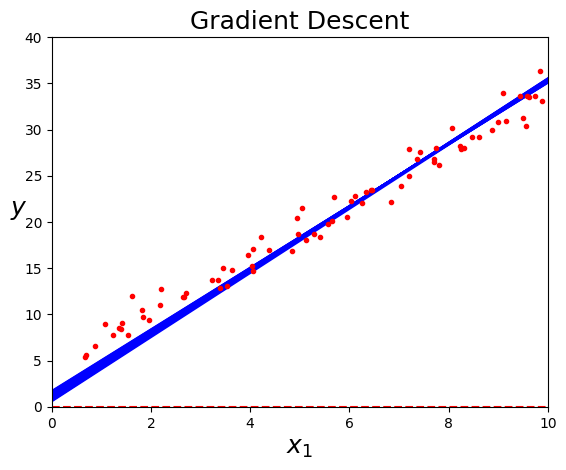

In [146]:
X_b = np.c_[np.ones((X.shape[0], 1)), X] # add X0 = 1 to each instance
X_new = np.array([[0],[10]])
X_new_b = np.c_[np.ones((2, 1)), X_new] # add x0 =1 to each instance

for j in range(0, len(w_all)):
    if j%10 != 0: continue
    y_hat = predict(X_new_b, w_all[j])
    style = "b-" if j > 0 else "r--"
    plt.plot(X_new_b[:,1], y_hat, style)

plt.plot(X_train[:, 1], y_train, "r.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18) 
plt.title('Gradient Descent', fontsize=18)
plt.axis([0,10,0,40])
plt.show

✅ Saved animation as gradient_descent.gif using pillow writer.


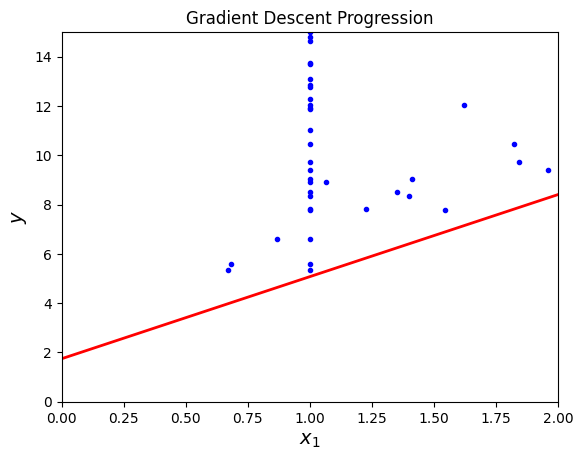

In [ ]:
# ---- Animation setup(AI generated : ChatGPT-5) ----
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]

fig, ax = plt.subplots()
ax.set_xlim(0, 2)
ax.set_ylim(0, 15)
ax.set_xlabel("$x_1$", fontsize=14)
ax.set_ylabel("$y$", fontsize=14)
ax.set_title("Gradient Descent Progression")
ax.plot(X_train, y_train, "b.", label="Training data")
line, = ax.plot([], [], "r-", lw=2)

def init():
    line.set_data([], [])
    return line,

def update(frame):
    w = w_all[frame]
    y_hat = predict(X_new_b, w)
    line.set_data(X_new_b[:, 1], y_hat)
    return line,

ani = animation.FuncAnimation(fig, update, frames=len(w_all), init_func=init,
                              blit=True, interval=100)

import shutil
import matplotlib.animation as animation

writer = "ffmpeg" if shutil.which("ffmpeg") else "pillow"
ext = "mp4" if writer == "ffmpeg" else "gif"

ani.save(f"gradient_descent.{ext}", writer=writer, fps=20)
print(f"✅ Saved animation as gradient_descent.{ext} using {writer} writer.")

plt.show()

### 2. Mini-Batch Gradient Descent Algorithms 


In [160]:
# --- Learning rate schedule ---
t0, t1 = 200, 100000

def learning_schedule(t):
    return t0 / (t + t1)

# --- Mini-Batch Gradient Descent ---
def mini_batch_gd(X: np.ndarray, y: np.ndarray, num_epochs: int, minibatch_size: int):
    """
    Estimates parameters of a linear regression model through mini-batch gradient descent.
    
    Args:
        X: Feature matrix for training data.
        y: Label vector for training data.
        num_epochs: Number of epochs (full passes over dataset).
        minibatch_size: Number of samples per mini-batch.
        
    Returns:
        w: Final weight vector.
        err_all: List of loss values over all updates.
        w_all: List of weight vectors over all updates.
    """
    w_all = []
    err_all = []
    w = np.zeros(X.shape[1])  # parameter vector
    t = 0  # iteration counter (used in learning rate schedule)
    
    for epoch in range(num_epochs):
        # shuffle data each epoch
        shuffled_indices = np.random.permutation(X.shape[0])
        X_shuffled = X[shuffled_indices]
        y_shuffled = y[shuffled_indices]

        for i in range(0, X.shape[0], minibatch_size):
            t += 1
            xi = X_shuffled[i:i+minibatch_size]
            yi = y_shuffled[i:i+minibatch_size]
            
            # compute gradient (no extra scaling needed; we'll handle normalization inside calculate_gradient)
            gradients = gradient(xi, yi, w)
            
            # update learning rate according to schedule
            lr = learning_schedule(t)
            
            # weight update
            w = update(w, gradients, lr)
            
            # record current weights and loss
            w_all.append(w.copy())
            err_all.append(loss(X, y, w))  # track total loss (optional: could use mini-batch loss)
        
        # print progress every epoch
        if epoch % 10 == 0:
            print(f"Epoch {epoch:4d} | Loss: {err_all[-1]:.6f} | LR: {lr:.6e}")
            
    return w, err_all, w_all


Epoch    0 | Loss: 49.539660 | LR: 1.999800e-03
Epoch   10 | Loss: 2.014623 | LR: 1.997802e-03


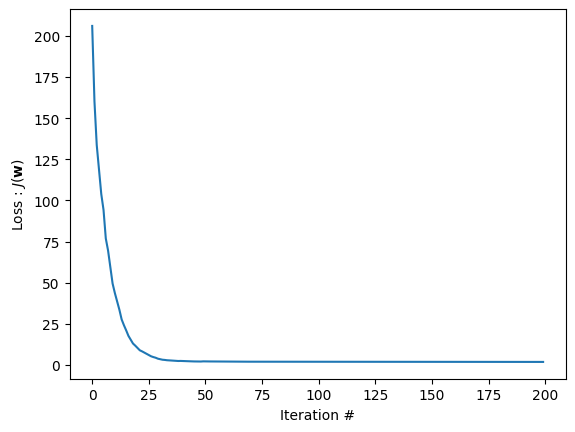

In [161]:
# learning curves

w, err_all, w_all = mini_batch_gd(X_train, y_train, 20, 8)
plot_learning(err_all)

Epoch    0 | Loss: 2.037647 | LR: 1.998501e-03
Epoch   10 | Loss: 1.435962 | LR: 1.983635e-03
Epoch   20 | Loss: 1.107138 | LR: 1.968988e-03
Epoch   30 | Loss: 0.989885 | LR: 1.954557e-03
Epoch   40 | Loss: 0.826224 | LR: 1.940335e-03
Epoch   50 | Loss: 0.792698 | LR: 1.926318e-03
Epoch   60 | Loss: 0.745852 | LR: 1.912503e-03
Epoch   70 | Loss: 0.765993 | LR: 1.898884e-03
Epoch   80 | Loss: 0.831040 | LR: 1.885458e-03
Epoch   90 | Loss: 0.970275 | LR: 1.872221e-03
Epoch    0 | Loss: 2.880172 | LR: 1.999240e-03
Epoch   10 | Loss: 1.737925 | LR: 1.991675e-03
Epoch   20 | Loss: 1.455231 | LR: 1.984166e-03
Epoch   30 | Loss: 1.255485 | LR: 1.976714e-03
Epoch   40 | Loss: 1.112294 | LR: 1.969318e-03
Epoch   50 | Loss: 1.016245 | LR: 1.961977e-03
Epoch   60 | Loss: 0.931780 | LR: 1.954690e-03
Epoch   70 | Loss: 0.883178 | LR: 1.947458e-03
Epoch   80 | Loss: 0.833257 | LR: 1.940278e-03
Epoch   90 | Loss: 0.798195 | LR: 1.933152e-03
Epoch    0 | Loss: 13.850547 | LR: 1.999620e-03
Epoch   10 |

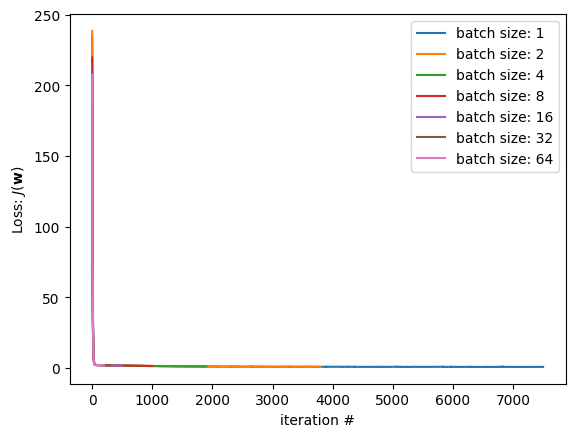

In [ ]:
# different batch sizes to find the optimal batch size for model training
batch_sizes = [1, 2, 4, 8, 16, 32, 64]
mbgd_stats = {}

for batch_size in batch_sizes:
    w, err_all, w_all = mini_batch_gd(X_train, y_train, 100, batch_size)
    mbgd_stats[batch_size] = err_all
    legend = 'batch size: %d' %batch_size
    plt.plot(err_all, label=legend)

plt.xlabel('iteration #')
plt.ylabel('Loss: $J(\mathbf{w})$')
plt.legend()

### Stochastic Gradient Descent

In [183]:
def sgd(X: np.ndarray, y: np.ndarray, num_epochs: int):
    """
    Estimates parameters of linear regression model through stochastic gradient descent.
    
    Args:
        X : ndarray
            Feature matrix for training data.
        y : ndarray
            Label vector for training data.
        num_epochs : int
            Number of passes over the dataset.
    
    Returns:
        w : ndarray
            Final weight vector.
        err_all : list
            Loss values across iterations.
        w_all : list
            Weight vectors across iterations.
    """
    w_all = []
    err_all = []
    
    w = np.zeros(X.shape[1])  # initialize weights
    t = 0  # iteration counter
    #shuffled_indices = np.random.permutation(X.shape[0])
    #y_shuffled = y[shuffled_indices]

    for epoch in range(num_epochs):
        # shuffle the data each epoch for better convergence
        shuffled_indices = np.random.permutation(X.shape[0])
        X_shuffled = X[shuffled_indices]
        y_shuffled = y[shuffled_indices]
        
        for i in range(X.shape[0]):
            t += 1
            xi = X_shuffled[i:i+1]   # single sample (kept 2D)
            yi = y_shuffled[i:i+1]
            
            # compute gradient (no need to multiply by 2)
            gradients = gradient(xi, yi, w)
            
            # update learning rate according to schedule
            lr = learning_schedule(t)
            
            # update weights
            w = update(w, gradients, lr)
            
            # record progress
            w_all.append(w.copy())
            err_all.append(loss(X, y, w))  # can also use loss(xi, yi, w) for local loss
        
        # print progress every few epochs
        if epoch % 10 == 0:
            print(f"Epoch {epoch:4d} | Loss: {err_all[-1]:.6f} | LR: {lr:.6e}")
    
    return w, err_all, w_all


In [184]:
shuffled_indices = np.random.permutation(X.shape[0])
y_shuffled = y[shuffled_indices]

In [188]:
w_sgd, err_sgd, w_all_sgd = sgd(X_train, y_train, num_epochs=50)


Epoch    0 | Loss: 2.141380 | LR: 1.998501e-03
Epoch   10 | Loss: 1.473245 | LR: 1.983635e-03
Epoch   20 | Loss: 1.106609 | LR: 1.968988e-03
Epoch   30 | Loss: 0.929750 | LR: 1.954557e-03
Epoch   40 | Loss: 0.830542 | LR: 1.940335e-03


Epoch    0 | Loss: 2.103857 | LR: 1.998501e-03
Epoch   10 | Loss: 1.453954 | LR: 1.983635e-03
Epoch   20 | Loss: 1.118728 | LR: 1.968988e-03
Epoch   30 | Loss: 0.934860 | LR: 1.954557e-03
Epoch   40 | Loss: 0.860288 | LR: 1.940335e-03
